# Rule-imposed vs. unconstrained speech

Each participant spoke ~30 s on five prompts (banana, table, tiger, tree, water) under two conditions: `rules` and `norules`.
Source: `labelled/*.txt` (reviewed verbatim transcripts) + metadata from `verbatim_transcripts.csv`.

Tags in transcripts: `[PAUSE x.xs]`, `[HESITATION: uh|um]`, `[CUT OFF]`, `[LAUGHTER]`, `[NO SPEECH: ...]`, partial words end in `-`.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_colwidth", 120)
ROOT = Path(".")
LABELLED = ROOT / "labelled"
meta = pd.read_csv(ROOT / "verbatim_transcripts.csv")
meta.shape

(50, 14)

## Load transcripts

In [2]:
rows = []
for f in sorted(LABELLED.glob("*.txt")):
    participant, session, prompt, condition = f.stem.split("_")
    rows.append(dict(id=f.stem, participant=participant, session=session,
                     prompt=prompt, condition=condition, raw=f.read_text().strip()))
df = pd.DataFrame(rows).merge(meta[["id", "duration_s", "review_notes"]], on="id", how="left")
df["no_speech"] = df.raw.str.contains(r"\[NO SPEECH", regex=True)
print(df.groupby(["participant", "condition"]).size().unstack())
print("\nNo-speech recordings (excluded from analysis):")
print(df.loc[df.no_speech, "id"].tolist())

condition    norules  rules
participant                
abhijith           5      5
akshara            5      5
ranesh             5      5
sanjith            5      5
venkat             5      5

No-speech recordings (excluded from analysis):
['ranesh_na_banana_rules', 'ranesh_na_table_rules', 'ranesh_na_tiger_rules', 'ranesh_na_tree_rules', 'ranesh_na_water_rules']


## Feature extraction

### Metric definitions

Words are counted from the transcript with all `[...]` tags removed; cut-off words (ending in `-`) are excluded from word counts. `duration` is the recording length in seconds from the CSV.

| Metric | Definition | What it indicates |
|---|---|---|
| `n_words` | Number of complete words | Overall verbal output in ~30 s |
| `speech_rate_wpm` | `60 × n_words / duration` | Speaking speed in words per minute; slower suggests more planning or monitoring |
| `n_pauses` | Count of `[PAUSE x.xs]` tags | How often the speaker stops |
| `total_pause_s` | Sum of all pause lengths (s) | Total silent time |
| `mean_pause_s` | `total_pause_s / n_pauses` (0 if no pauses) | Typical length of a stop; longer pauses suggest planning effort |
| `pause_frac` | `total_pause_s / duration` | Share of the recording spent silent |
| `n_hes` | Count of `[HESITATION: uh/um]` tags | Filled pauses |
| `hes_per_100w` | `100 × n_hes / n_words` | Filled pauses adjusted for how much was said |
| `n_partial` | Words ending in `-` (e.g. `la-`) | Broken-off words, i.e. self-interruptions and repairs |
| `type_token_ratio` | Unique words / total words | Vocabulary variety; sensitive to text length, so compare similar lengths |
| `mean_word_len` | Average letters per word | Rough proxy for lexical complexity |
| `mean_sent_len` | `n_words` / number of sentences (split on `.!?`) | Rough proxy for syntactic complexity; depends on transcriber punctuation |
| `cut_off_end` | Transcript ends with `[CUT OFF]` | Recording stopped mid-utterance (not compared statistically) |

**Paired-test columns:** `mean_diff` = mean of (rules − norules) across matched pairs; `effect_dz` = `mean_diff / sd(diff)` (Cohen's d_z; ~0.2 small, ~0.5 medium, ~0.8 large); `wilcoxon_p` = p-value of the Wilcoxon signed-rank test.

In [3]:
TAG = re.compile(r"\[[^\]]*\]")
PAUSE = re.compile(r"\[PAUSE ([\d.]+)s\]")
HES = re.compile(r"\[HESITATION: (\w+)\]")
WORD = re.compile(r"[A-Za-z]+(?:['-][A-Za-z]+)*-?")

def clean_text(raw):
    return re.sub(r"\s+", " ", TAG.sub(" ", raw)).strip()

def features(raw, dur):
    text = clean_text(raw)
    words = WORD.findall(text)
    full = [w.lower() for w in words if not w.endswith("-")]
    pauses = [float(p) for p in PAUSE.findall(raw)]
    sents = [s for s in re.split(r"[.!?]+", text) if WORD.search(s)]
    n = max(len(full), 1)
    return dict(
        text=text,
        n_words=len(full),
        speech_rate_wpm=60 * len(full) / dur,
        n_pauses=len(pauses),
        total_pause_s=sum(pauses),
        mean_pause_s=np.mean(pauses) if pauses else 0.0,
        pause_frac=sum(pauses) / dur,
        n_hes=len(HES.findall(raw)),
        hes_per_100w=100 * len(HES.findall(raw)) / n,
        n_partial=sum(w.endswith("-") for w in words),
        type_token_ratio=len(set(full)) / n,
        mean_word_len=np.mean([len(w) for w in full]) if full else 0.0,
        mean_sent_len=len(full) / max(len(sents), 1),
        cut_off_end=raw.rstrip().endswith("[CUT OFF]"),
    )

feat = df.join(df.apply(lambda r: pd.Series(features(r.raw, r.duration_s)), axis=1))
data = feat[~feat.no_speech].copy()
METRICS = ["n_words", "speech_rate_wpm", "n_pauses", "total_pause_s", "mean_pause_s", "pause_frac",
           "n_hes", "hes_per_100w", "n_partial", "type_token_ratio", "mean_word_len", "mean_sent_len"]
data[["id"] + METRICS].head()

,id,n_words,speech_rate_wpm,n_pauses,total_pause_s,mean_pause_s,pause_frac,n_hes,hes_per_100w,n_partial,type_token_ratio,mean_word_len,mean_sent_len
0,abhijith_day1_banana_norules,69,135.719906,7,6.7,0.957143,0.219643,0,0.0,0,0.753623,4.304348,23.00
1,abhijith_day1_banana_rules,47,91.725215,7,8.0,1.142857,0.260213,0,0.0,0,0.787234,5.042553,11.75
2,abhijith_day1_table_norules,56,109.119252,9,6.4,0.711111,0.207846,0,0.0,0,0.803571,4.803571,11.20
3,abhijith_day1_table_rules,59,114.518634,3,2.3,0.766667,0.074405,0,0.0,0,0.728814,4.525424,14.75
4,abhijith_day1_tiger_norules,57,109.953704,8,7.3,0.912500,0.234697,0,0.0,0,0.771930,4.929825,19.00


## Condition-level summary

In [4]:
data.groupby("condition")[METRICS].agg(["mean", "std"]).T.round(3)

condition              norules    rules
n_words          mean   77.280   72.250
                 std    19.733   20.021
speech_rate_wpm  mean  144.045  129.692
                 std    34.648   31.136
n_pauses         mean    4.480    4.600
                 std     2.931    2.798
total_pause_s    mean    3.428    3.960
                 std     2.460    2.547
mean_pause_s     mean    0.623    0.766
                 std     0.296    0.327
pause_frac       mean    0.108    0.121
                 std     0.080    0.079
n_hes            mean    2.880    2.650
                 std     2.166    2.134
hes_per_100w     mean    3.919    3.784
                 std     3.514    3.411
n_partial        mean    0.720    0.300
                 std     0.792    0.571
type_token_ratio mean    0.703    0.685
                 std     0.064    0.063
mean_word_len    mean    4.728    4.724
                 std     0.359    0.278
mean_sent_len    mean   21.966   19.328
                 std     7.788    6.741

## Paired comparison
Rows are paired by participant × prompt (only pairs where both recordings contain speech). Wilcoxon signed-rank test on `rules − norules`.
With ~20 pairs, treat p-values as exploratory.

In [5]:
wide = data.pivot_table(index=["participant", "prompt"], columns="condition", values=METRICS).dropna()
res = []
for m in METRICS:
    r, n = wide[(m, "rules")], wide[(m, "norules")]
    d = r - n
    p = stats.wilcoxon(r, n).pvalue if (d != 0).any() else np.nan
    res.append(dict(metric=m, rules_mean=r.mean(), norules_mean=n.mean(), mean_diff=d.mean(),
                    effect_dz=d.mean() / d.std(ddof=1) if d.std() > 0 else np.nan, wilcoxon_p=p))
paired = pd.DataFrame(res).set_index("metric").round(3)
print(f"{len(wide)} pairs")
paired

20 pairs


,rules_mean,norules_mean,mean_diff,effect_dz,wilcoxon_p
metric,,,,,
n_words,72.250,78.700,-6.450,-0.414,0.172
speech_rate_wpm,129.692,144.729,-15.038,-0.536,0.076
n_pauses,4.600,4.650,-0.050,-0.017,0.775
total_pause_s,3.960,3.510,0.450,0.176,0.396
mean_pause_s,0.766,0.618,0.148,0.474,0.016
pause_frac,0.121,0.109,0.012,0.147,0.398
n_hes,2.650,2.550,0.100,0.064,0.715
hes_per_100w,3.784,3.438,0.345,0.129,0.679
n_partial,0.300,0.700,-0.400,-0.487,0.046


## Plots

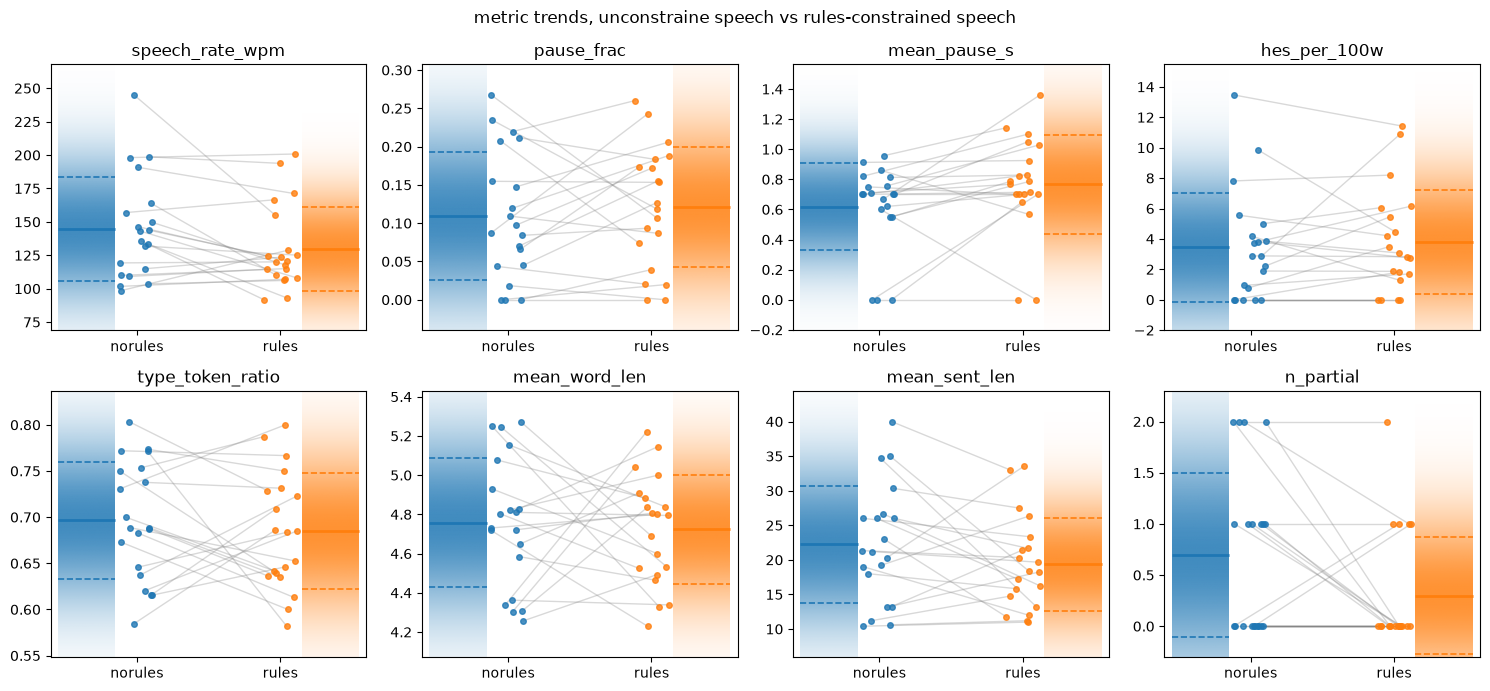

In [6]:
from matplotlib.colors import to_rgb

COLORS = {"norules": "tab:blue", "rules": "tab:orange"}

def gaussian_strip(ax, values, x0, x1, color, ylim):
    """Shade a vertical strip [x0, x1] with alpha proportional to the fitted normal pdf."""
    mu, sd = np.mean(values), np.std(values, ddof=1)
    if not sd > 0:
        return
    y = np.linspace(*ylim, 300)
    dens = stats.norm.pdf(y, mu, sd)
    img = np.zeros((len(y), 1, 4))
    img[..., :3] = to_rgb(color)
    img[:, 0, 3] = 0.85 * dens / dens.max()
    ax.imshow(img, extent=(x0, x1, ylim[0], ylim[1]), origin="lower", aspect="auto", zorder=0)
    ax.hlines(mu, x0, x1, color=color, lw=2, zorder=1)
    ax.hlines([mu - sd, mu + sd], x0, x1, color=color, lw=1.2, ls="--", zorder=1)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
show = ["speech_rate_wpm", "pause_frac", "mean_pause_s", "hes_per_100w",
        "type_token_ratio", "mean_word_len", "mean_sent_len", "n_partial"]
for ax, m in zip(axes.flat, show):
    a, b = wide[(m, "norules")], wide[(m, "rules")]
    allv = np.concatenate([a, b])
    pad = 0.15 * (allv.max() - allv.min() or 1)
    ylim = (allv.min() - pad, allv.max() + pad)
    gaussian_strip(ax, a, -0.55, -0.15, COLORS["norules"], ylim)
    gaussian_strip(ax, b, 1.15, 1.55, COLORS["rules"], ylim)
    rng = np.random.default_rng(0)  # fixed seed -> same jitter every run
    xa = rng.uniform(-0.12, 0.12, len(a))
    xb = 1 + rng.uniform(-0.12, 0.12, len(b))
    for i in range(len(a)):
        ax.plot([xa[i], xb[i]], [a.iloc[i], b.iloc[i]], color="grey", alpha=0.3, lw=1, zorder=2)
    ax.scatter(xa, a, color=COLORS["norules"], s=16, alpha=0.8, zorder=3)
    ax.scatter(xb, b, color=COLORS["rules"], s=16, alpha=0.8, zorder=3)
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(ylim)
    ax.set_xticks([0, 1], ["norules", "rules"])
    ax.set_title(m)
fig.suptitle("metric trends, unconstraine speech vs rules-constrained speech")
fig.tight_layout()

In [7]:
# Per-participant mean difference (rules - norules)
diff = pd.DataFrame({m: wide[(m, "rules")] - wide[(m, "norules")] for m in METRICS})
diff.groupby("participant").mean().round(2)

,n_words,speech_rate_wpm,n_pauses,total_pause_s,mean_pause_s,pause_frac,n_hes,hes_per_100w,n_partial,type_token_ratio,mean_word_len,mean_sent_len
participant,,,,,,,,,,,,
abhijith,-2.0,-5.12,-3.6,-2.40,0.11,-0.08,0.2,0.36,0.0,-0.00,0.02,-2.70
akshara,-17.4,-30.62,0.4,1.32,0.20,0.04,-0.6,0.19,-0.6,0.06,0.18,-1.07
sanjith,-1.6,-3.99,2.8,2.76,0.14,0.08,0.4,0.42,-0.6,-0.09,-0.15,-2.83
venkat,-4.8,-20.43,0.2,0.12,0.14,0.00,0.4,0.41,-0.4,-0.02,-0.18,-5.15


## Lexical differences

In [8]:
from collections import Counter

def tokens(texts):
    return [w.lower() for t in texts for w in WORD.findall(t) if not w.endswith("-")]

cnt = {c: Counter(tokens(data.loc[data.condition == c, "text"])) for c in ["rules", "norules"]}
tot = {c: sum(v.values()) for c, v in cnt.items()}
vocab = set(cnt["rules"]) | set(cnt["norules"])
lo = pd.DataFrame({
    w: {"rules": cnt["rules"][w], "norules": cnt["norules"][w],
        # smoothed log-odds ratio, rules vs norules
        "log_odds": np.log((cnt["rules"][w] + 0.5) / (tot["rules"] - cnt["rules"][w] + 0.5))
                  - np.log((cnt["norules"][w] + 0.5) / (tot["norules"] - cnt["norules"][w] + 0.5))}
    for w in vocab}).T
lo = lo[(lo.rules + lo.norules) >= 4].sort_values("log_odds")
print("More frequent in NORULES:"); display(lo.head(15))
print("More frequent in RULES:"); display(lo.tail(15)[::-1])

More frequent in NORULES:


,rules,norules,log_odds
even,0.0,7.0,-2.421320
now,0.0,7.0,-2.421320
over,0.0,7.0,-2.421320
or,0.0,6.0,-2.277700
examples,0.0,6.0,-2.277700
it's,0.0,5.0,-2.110127
seeds,0.0,4.0,-1.908937
right,0.0,4.0,-1.908937
types,0.0,4.0,-1.908937
some,0.0,4.0,-1.908937


More frequent in RULES:


,rules,norules,log_odds
where,7.0,0.0,3.003264
an,7.0,0.0,3.003264
nation,7.0,1.0,1.904134
find,6.0,1.0,1.760338
called,12.0,3.0,1.570108
this,10.0,3.0,1.394360
known,4.0,1.0,1.391225
yeah,3.0,1.0,1.139217
store,3.0,1.0,1.139217
up,3.0,1.0,1.139217


## Browse transcripts side by side

In [9]:
def show_pair(participant, prompt):
    for c in ["norules", "rules"]:
        r = feat[(feat.participant == participant) & (feat.prompt == prompt) & (feat.condition == c)].iloc[0]
        print(f"--- {c} ({r.duration_s:.1f}s) ---\n{r.raw}\n")

show_pair("abhijith", "banana")

--- norules (30.5s) ---
[CUT OFF] Bananas are delicious fruits that are eaten across the world [PAUSE 0.5s] all the way from Brazil to Indonesia to America, [PAUSE 1.4s] but it makes you wonder [PAUSE 0.9s] how did it become such a popular fruit, [PAUSE 0.8s] well I don't know, I am asking the question too. [PAUSE 1.1s] And [PAUSE 1.2s] bananas used to have big big seeds but now they don't. Now we can eat the seeds [PAUSE 0.8s] and they're practically nonexistent which again makes me wonder.

--- rules (30.7s) ---
Bananas are beautiful fruits which are eaten around the world. [PAUSE 0.7s] Indigenous people originally harvested bananas for their own consumption, [PAUSE 0.6s] but the British foreigners stole the bananas from them [PAUSE 0.6s] and [PAUSE 0.8s] used it to pillage and rape. [PAUSE 1.5s] countries around the world. [PAUSE 2.5s] The [PAUSE 1.3s] banana is a vital diet item of [CUT OFF]



## Morphological analysis: agglutination vs. fusion (plan)

**Goal:** split each word into morphemes, then label each morpheme boundary as *agglutinative* (clean concatenation, one meaning per piece: `un-help-ful-ness`) or *fusional* (the boundary is blurred or one form carries several meanings: `went`, `mice`, `decide → decis-ion`).

**Proposed pipeline (hybrid):**
1. **Inflection: spaCy** (`en_core_web_sm`). Each token gets a lemma and morphological features (`Tense=Past`, `Number=Plur`, …).
   - If the word is lemma + a regular suffix (`walk+ed`, `tree+s`), the boundary is agglutinative.
   - If the lemma is not a prefix of the word (`went/go`, `children/child`, `ran/run`), the word is fusional, with features carried by a single form.
2. **Derivation: MorphoLex-EN** (Sánchez-Gutiérrez et al., 2018; about 70k English words with prefix/root/suffix segmentation), with **MorphyNet** (from Wiktionary) as a backup. Look up each lemma to get segmentations such as `{un}<help>{ful}{ness}`.
   - If the morphs concatenate exactly to the surface form, the boundary is agglutinative.
   - If they need a spelling or sound change (`decide+ion → decision`, `happy+ness → happiness`), the boundary is fusional. These can be split into spelling-only and true stem changes.
3. **Fallback: Morfessor 2.0** (unsupervised, statistical) for words in neither lexicon, such as names and disfluent fragments. These words are flagged, because their segmentations are less reliable.

**Per-word outputs:** `n_morphemes`, `n_agglutinative_junctures`, `n_fusional_junctures`, `source` (lexicon / spaCy / morfessor).

**Per-transcript indices (Greenberg-style):**
- *Synthesis index* = morphemes / word
- *Agglutination index* = agglutinative junctures / all junctures
- *Fusion rate* = share of words containing at least one fusional juncture

These would then go through the same paired rules vs. norules tests and plots used above.

**Caveats:** English is mostly analytic, so expect low counts and many single-morpheme words. Function words dominate, so it is also worth computing the indices for content words only.

In [10]:
# Setup: spaCy, MorphoLex-EN lexicon, Morfessor fallback (cached in ./data)
# Requires: pip install spacy morfessor openpyxl && python -m spacy download en_core_web_sm
import warnings, morfessor, spacy
DATA = ROOT / "data"
nlp = spacy.load("en_core_web_sm")

SEGM_CSV = DATA / "morpholex_segm.csv"
if not SEGM_CSV.exists():  # flatten the multi-sheet xlsx once
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sheets = pd.read_excel(DATA / "MorphoLEX_en.xlsx", sheet_name=None)
    pd.concat([v[["Word", "POS", "Nmorph", "MorphoLexSegm"]] for v in sheets.values()
               if "MorphoLexSegm" in v.columns]).to_csv(SEGM_CSV, index=False)
mlex = pd.read_csv(SEGM_CSV).dropna(subset=["Word", "MorphoLexSegm"])
LEX = dict(zip(mlex.Word.astype(str).str.lower(), mlex.MorphoLexSegm))

MORF_BIN = DATA / "morfessor_model.bin"
io = morfessor.MorfessorIO()
if MORF_BIN.exists():
    morf = io.read_binary_model_file(str(MORF_BIN))
else:  # train on MorphoLex word types (~40 s)
    morf = morfessor.BaselineModel()
    morf.load_data([(1, w) for w in LEX if w.isalpha()])
    morf.train_batch(max_epochs=4)
    io.write_binary_model_file(str(MORF_BIN), morf)
print(f"MorphoLex entries: {len(LEX):,}")

MorphoLex entries: 68,623


In [11]:
# Segmentation + juncture classification
SEG_RE = re.compile(r"<([^<>]+)<|\(([^()]+)\)|>([^<>]+)>")
INFL_POS = {"VERB", "AUX", "NOUN", "ADJ", "ADV", "PRON"}
CONTENT_POS = {"NOUN", "VERB", "ADJ", "ADV"}

def parse_morpholex(seg):
    """'{<un<(help)>ful>}' -> ['un', 'help', 'ful']"""
    s = seg.replace("{", "").replace("}", "")
    return [next(g for g in m if g) for m in SEG_RE.findall(s)]

def ortho_variants(m):
    """Spelling-only changes of a left morph at a boundary: e-deletion, y->i, consonant doubling."""
    v = []
    if m.endswith("e"): v.append(m[:-1])
    if m.endswith("y"): v.append(m[:-1] + "i")
    if len(m) > 1 and m[-1] not in "aeiouwy": v.append(m + m[-1])
    return v

def classify_juncture(left, right, form):
    """Is left+right visible in the surface form intact, with a spelling tweak, or not at all?"""
    r = right[:3]
    if left + r in form:
        return "agg"
    if any(v + r in form for v in ortho_variants(left)):
        return "ortho"
    return "fus"

def classify_inflection(word, lemma, tok):
    """None if uninflected; else agg / ortho / fus for the stem+inflection boundary."""
    if tok.pos_ not in INFL_POS:
        return None
    if word == lemma:
        # zero-marked past / plural (put, sheep) = features fused into the bare form
        past = "Past" in tok.morph.get("Tense") and tok.pos_ in {"VERB", "AUX"}
        plur = "Plur" in tok.morph.get("Number") and tok.pos_ == "NOUN"
        return "fus" if (past or plur) else None
    if word.startswith(lemma):
        return "agg"                                  # walk-ed, tree-s
    if any(word.startswith(v) for v in ortho_variants(lemma)):
        return "ortho"                                # mak-ing, stud-ies, run-n-ing
    return "fus"                                      # went, children, was, him

def analyse_token(tok):
    word, lemma = tok.text.lower(), tok.lemma_.lower()
    if tok.pos_ == "PROPN":
        morphs, src = [word], "propn"
    elif lemma in LEX or word in LEX:
        key = lemma if lemma in LEX else word
        morphs, src = parse_morpholex(LEX[key]), "morpholex"
    else:
        morphs, src = morf.viterbi_segment(lemma)[0], "morfessor"
    base = lemma if src != "propn" else word
    # Morfessor segments always concatenate exactly, so its junctures are 'unverified'
    junc = ([classify_juncture(a, b, base) for a, b in zip(morphs, morphs[1:])]
            if src == "morpholex" else ["unverified"] * (len(morphs) - 1))
    infl = classify_inflection(word, lemma, tok) if src != "propn" else None
    if infl:
        junc.append(infl)
    return dict(word=word, lemma=lemma, pos=tok.pos_, source=src,
                morphemes="+".join(morphs) + (f"+[{','.join(str(tok.morph).split('|'))}]" if infl else ""),
                n_morphemes=len(morphs) + bool(infl),
                n_agg=junc.count("agg"), n_ortho=junc.count("ortho"),
                n_fus=junc.count("fus"), n_unverified=junc.count("unverified"),
                content=tok.pos_ in CONTENT_POS)

PARTIAL = re.compile(r"\b[A-Za-z']+-(?=\s|$)")
tok_rows = []
for rid, text in zip(data.id, data.text):
    for tok in nlp(PARTIAL.sub(" ", text)):
        if tok.is_alpha:
            tok_rows.append(dict(id=rid, **analyse_token(tok)))
morph_tok = pd.DataFrame(tok_rows)
print(morph_tok.source.value_counts(), "\n")
morph_tok[morph_tok.n_morphemes > 1].drop_duplicates("word").sample(15, random_state=1)

source
morpholex    3279
propn          86
morfessor      15
Name: count, dtype: int64 



,id,word,lemma,pos,source,morphemes,n_morphemes,n_agg,n_ortho,n_fus,n_unverified,content
3060,venkat_day1_tree_rules,backyard,backyard,NOUN,morpholex,back+yard,2,1,0,0,0,True
2720,venkat_day1_table_rules,computer,computer,NOUN,morpholex,compute+er,2,0,1,0,0,True
148,abhijith_day1_table_norules,materials,material,NOUN,morpholex,material+[Number=Plur],2,1,0,0,0,True
2237,sanjith_day1_water_norules,glasses,glass,NOUN,morpholex,glass+[Number=Plur],2,1,0,0,0,True
2993,venkat_day1_tree_norules,affected,affect,VERB,morpholex,"a+fect+[Aspect=Perf,Tense=Past,VerbForm=Part]",3,1,0,1,0,True
2395,venkat_day1_banana_norules,ghosts,ghost,NOUN,morpholex,ghost+[Number=Plur],2,1,0,0,0,True
2184,sanjith_day1_tree_rules,monkeys,monkey,NOUN,morpholex,monkey+[Number=Plur],2,1,0,0,0,True
349,abhijith_day1_tree_norules,provide,provide,VERB,morpholex,pro+vide,2,1,0,0,0,True
1515,ranesh_na_tiger_norules,packs,pack,NOUN,morpholex,pack+[Number=Plur],2,1,0,0,0,True
142,abhijith_day1_table_norules,offices,office,NOUN,morpholex,office+[Number=Plur],2,1,0,0,0,True


In [12]:
# Inspect: fusional words, and what fell back to Morfessor (worth eyeballing for errors)
print("Fusional words:")
display(morph_tok[morph_tok.n_fus > 0].groupby(["word", "lemma", "morphemes"]).size()
        .sort_values(ascending=False).head(20).rename("count").to_frame())
print("Morfessor fallbacks:", sorted(morph_tok.loc[morph_tok.source == "morfessor", "word"].unique()))

Fusional words:


,,,count
word,lemma,morphemes,
are,be,"be+[Mood=Ind,Tense=Pres,VerbForm=Fin]",114
is,be,"be+[Mood=Ind,Number=Sing,Person=3,Tense=Pres,VerbForm=Fin]",55
found,find,"find+[Aspect=Perf,Tense=Past,VerbForm=Part]",24
has,have,"have+[Mood=Ind,Number=Sing,Person=3,Tense=Pres,VerbForm=Fin]",14
different,different,differ+ant,12
various,various,vary+ious,10
made,make,"make+[Aspect=Perf,Tense=Past,VerbForm=Part]",9
people,people,people+[Number=Plur],7
variety,variety,vary+ity,7


Morfessor fallbacks: ['banyan', 'c', 'eigenvectors', 'ginormous', 'incan', 'majorly', 'multinational', 'peepal', 'phytoplankton', 'pr', 'r', 'rainforests', 'regrow']


### Per-transcript indices
- `synthesis` = morphemes / word
- `agglutination` = (agg + ortho) / all verified junctures (spelling-only changes count as agglutinative)
- `ortho_share` = ortho / verified junctures
- `fusion_rate` = share of words with ≥ 1 fusional juncture
- `multimorph_rate` = share of words with > 1 morpheme

`_c` suffix = content words only (NOUN, VERB, ADJ, ADV). Morfessor junctures are excluded from the juncture-based indices but their morphemes count toward synthesis.

In [13]:
def morph_indices(g):
    verified = g.n_agg.sum() + g.n_ortho.sum() + g.n_fus.sum()
    return pd.Series(dict(
        synthesis=g.n_morphemes.mean(),
        agglutination=(g.n_agg.sum() + g.n_ortho.sum()) / verified if verified else np.nan,
        ortho_share=g.n_ortho.sum() / verified if verified else np.nan,
        fusion_rate=(g.n_fus > 0).mean(),
        multimorph_rate=(g.n_morphemes > 1).mean(),
    ))

mi = morph_tok.groupby("id").apply(morph_indices)
mi_c = morph_tok[morph_tok.content].groupby("id").apply(morph_indices).add_suffix("_c")
morph_df = data[["id", "participant", "prompt", "condition"]].merge(mi.join(mi_c), on="id")
MORPH_METRICS = [c for c in morph_df.columns if c not in ("id", "participant", "prompt", "condition")]
morph_df.groupby("condition")[MORPH_METRICS].agg(["mean", "std"]).T.round(3)

condition               norules  rules
synthesis         mean    1.419  1.398
                  std     0.102  0.078
agglutination     mean    0.684  0.649
                  std     0.076  0.099
ortho_share       mean    0.051  0.058
                  std     0.037  0.061
fusion_rate       mean    0.126  0.126
                  std     0.042  0.040
multimorph_rate   mean    0.352  0.351
                  std     0.068  0.065
synthesis_c       mean    1.672  1.653
                  std     0.176  0.149
agglutination_c   mean    0.795  0.746
                  std     0.084  0.098
ortho_share_c     mean    0.064  0.068
                  std     0.049  0.069
fusion_rate_c     mean    0.130  0.143
                  std     0.067  0.059
multimorph_rate_c mean    0.539  0.556
                  std     0.096  0.102

In [14]:
# Paired rules vs norules tests (same method as above)
mwide = morph_df.pivot_table(index=["participant", "prompt"], columns="condition", values=MORPH_METRICS).dropna()
res = []
for m in MORPH_METRICS:
    r, n = mwide[(m, "rules")], mwide[(m, "norules")]
    d = r - n
    p = stats.wilcoxon(r, n).pvalue if (d != 0).any() else np.nan
    res.append(dict(metric=m, rules_mean=r.mean(), norules_mean=n.mean(), mean_diff=d.mean(),
                    effect_dz=d.mean() / d.std(ddof=1) if d.std() > 0 else np.nan, wilcoxon_p=p))
print(f"{len(mwide)} pairs")
pd.DataFrame(res).set_index("metric").round(4)

20 pairs


,rules_mean,norules_mean,mean_diff,effect_dz,wilcoxon_p
metric,,,,,
synthesis,1.3984,1.4148,-0.0164,-0.1264,0.5217
agglutination,0.6494,0.6807,-0.0314,-0.2455,0.3488
ortho_share,0.0583,0.0487,0.0096,0.1506,0.4380
fusion_rate,0.1263,0.1247,0.0017,0.0260,0.7562
multimorph_rate,0.3508,0.3461,0.0047,0.0507,0.9563
synthesis_c,1.6526,1.6651,-0.0125,-0.0658,0.7562
agglutination_c,0.7460,0.8028,-0.0568,-0.4588,0.0486
ortho_share_c,0.0680,0.0619,0.0061,0.0758,0.5695
fusion_rate_c,0.1426,0.1232,0.0194,0.2130,0.5459


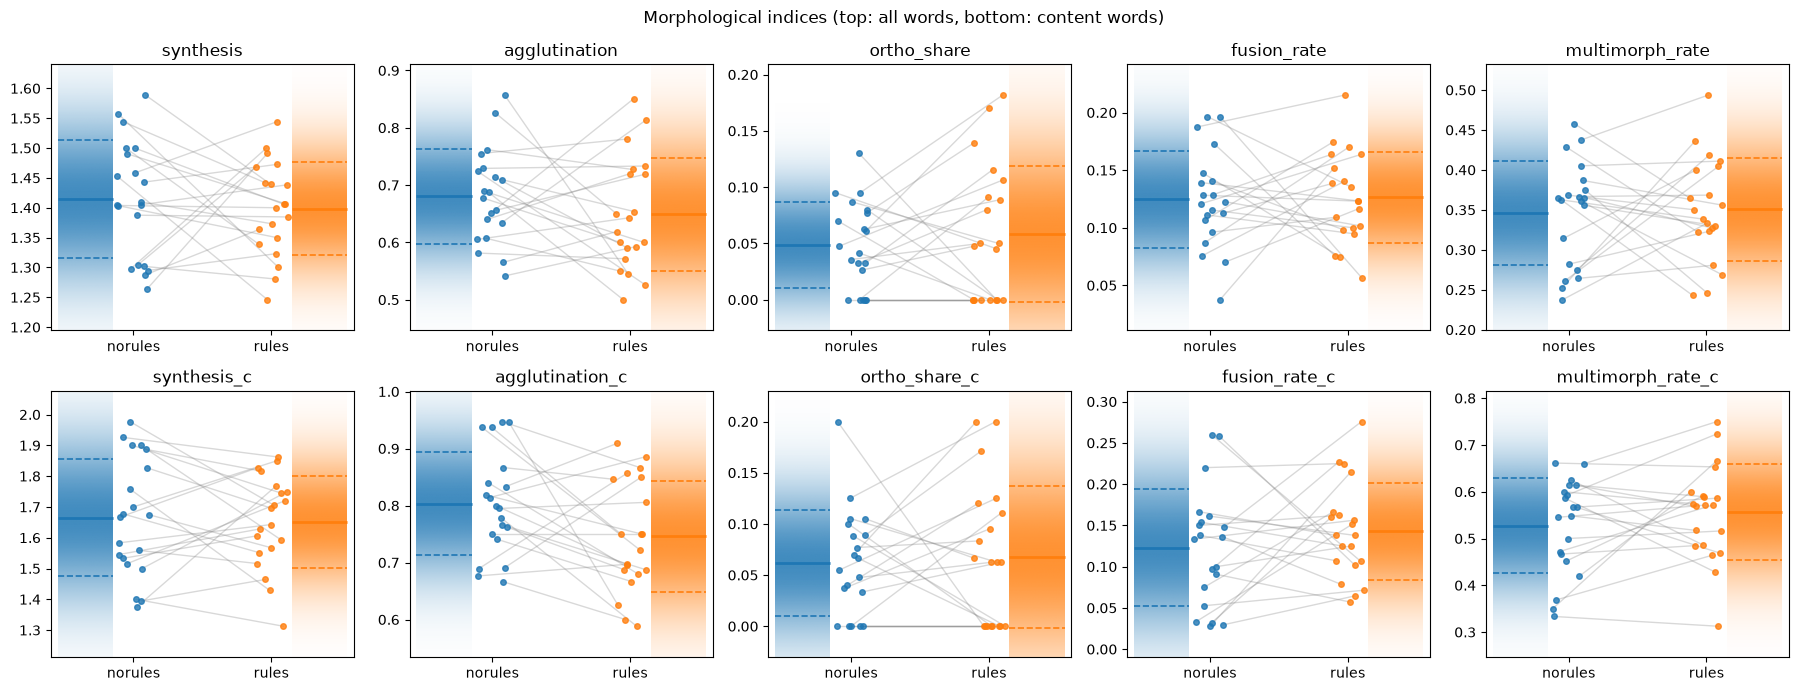

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
rng = np.random.default_rng(0)
for ax, m in zip(axes.flat, MORPH_METRICS):
    a, b = mwide[(m, "norules")], mwide[(m, "rules")]
    allv = np.concatenate([a, b])
    pad = 0.15 * (allv.max() - allv.min() or 1)
    ylim = (allv.min() - pad, allv.max() + pad)
    gaussian_strip(ax, a, -0.55, -0.15, COLORS["norules"], ylim)
    gaussian_strip(ax, b, 1.15, 1.55, COLORS["rules"], ylim)
    xa, xb = rng.uniform(-0.12, 0.12, len(a)), 1 + rng.uniform(-0.12, 0.12, len(b))
    for i in range(len(a)):
        ax.plot([xa[i], xb[i]], [a.iloc[i], b.iloc[i]], color="grey", alpha=0.3, lw=1, zorder=2)
    ax.scatter(xa, a, color=COLORS["norules"], s=16, alpha=0.8, zorder=3)
    ax.scatter(xb, b, color=COLORS["rules"], s=16, alpha=0.8, zorder=3)
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(ylim)
    ax.set_xticks([0, 1], ["norules", "rules"]); ax.set_title(m)
fig.suptitle("Morphological indices (top: all words, bottom: content words)")
fig.tight_layout()

**Known limitations**
- The juncture check is local (does `left + first 3 letters of right` appear in the word?). It can mis-tag boundaries next to a heavily altered morph.
- MorphoLex lists bound roots in their underlying form (`co+sume+ion` → *consumption*), so Latinate allomorphy counts as fusional. That is arguably correct, but it inflates fusion for academic vocabulary.
- spaCy lemmas sometimes treat pronoun case (`him → he`) and comparatives (`better → good`) as inflection, which tags them as fusional.
- Clitics (`n't`, `'s`) are separate non-alphabetic tokens in spaCy and are skipped.

## Breakdowns by participant and by prompt
Each grid: rows = groups, columns = metrics (y-axis shared per column so rows are comparable).
Points are paired norules → rules; marker shape identifies the prompt (participant grids) or participant (prompt grids).
With ≤ 5 points per panel, the Gaussian strips are rough guides only.

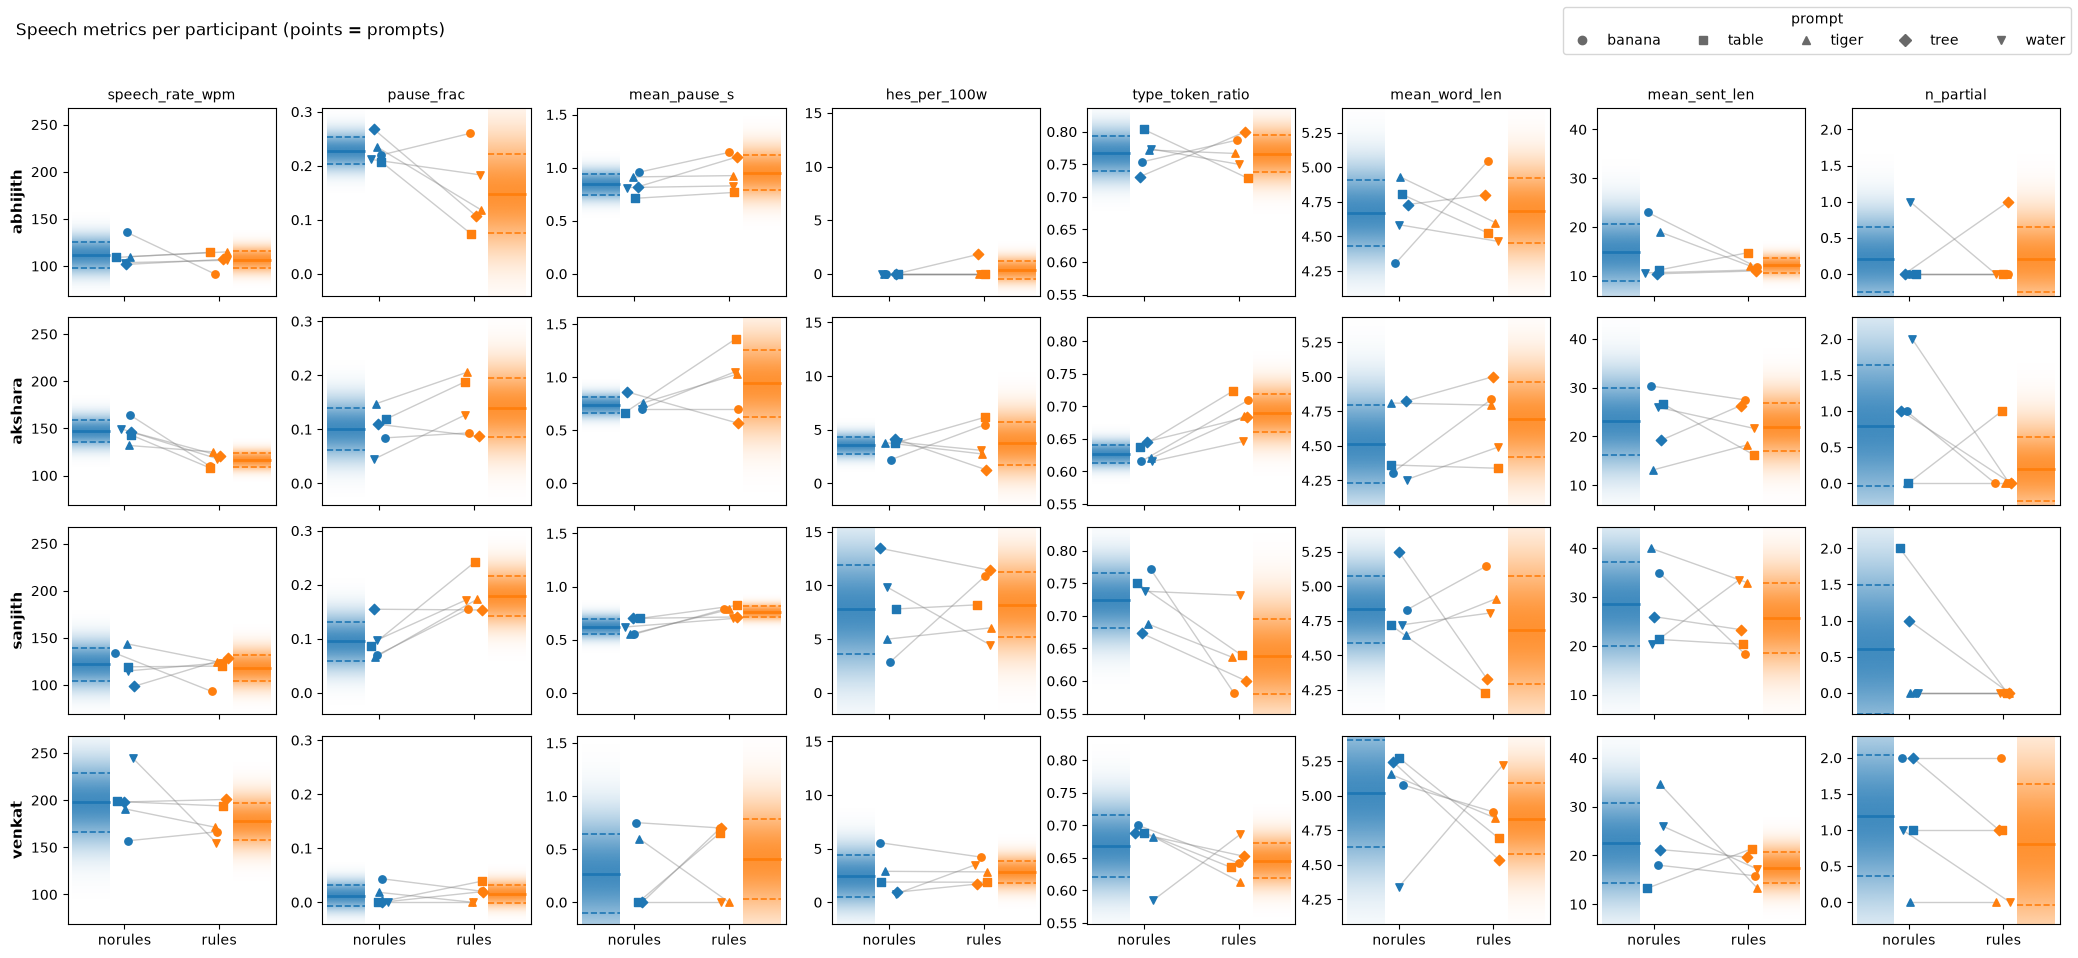

In [16]:
from matplotlib.lines import Line2D
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]

def breakdown_grid(wide_df, metrics, by, title):
    """by='participant' -> one row per participant, points = prompts (and vice versa)."""
    other = "prompt" if by == "participant" else "participant"
    groups = sorted(wide_df.index.get_level_values(by).unique())
    ids = sorted(wide_df.index.get_level_values(other).unique())
    mk = dict(zip(ids, MARKERS))
    fig, axes = plt.subplots(len(groups), len(metrics), figsize=(2.6 * len(metrics), 2.4 * len(groups)),
                             squeeze=False)
    rng = np.random.default_rng(0)
    for j, m in enumerate(metrics):
        allv = wide_df[m].to_numpy().ravel()
        pad = 0.15 * (allv.max() - allv.min() or 1)
        ylim = (allv.min() - pad, allv.max() + pad)
        for i, g in enumerate(groups):
            ax = axes[i, j]
            sub = wide_df[m].xs(g, level=by)
            a, b = sub["norules"], sub["rules"]
            gaussian_strip(ax, a, -0.55, -0.15, COLORS["norules"], ylim)
            gaussian_strip(ax, b, 1.15, 1.55, COLORS["rules"], ylim)
            for k in sub.index:
                xa, xb = rng.uniform(-0.1, 0.1), 1 + rng.uniform(-0.1, 0.1)
                ax.plot([xa, xb], [a[k], b[k]], color="grey", alpha=0.4, lw=1, zorder=2)
                ax.scatter([xa], [a[k]], marker=mk[k], color=COLORS["norules"], s=28, zorder=3)
                ax.scatter([xb], [b[k]], marker=mk[k], color=COLORS["rules"], s=28, zorder=3)
            ax.set_xlim(-0.6, 1.6); ax.set_ylim(ylim)
            ax.set_xticks([0, 1], ["norules", "rules"] if i == len(groups) - 1 else ["", ""])
            if i == 0: ax.set_title(m, fontsize=10)
            if j == 0: ax.set_ylabel(g, fontsize=11, fontweight="bold")
    handles = [Line2D([], [], marker=mk[k], ls="", color="dimgrey", label=k) for k in ids]
    fig.legend(handles=handles, title=other, loc="upper right", ncol=len(ids))
    fig.suptitle(title, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.96))

breakdown_grid(wide, show, "participant", "Speech metrics per participant (points = prompts)")

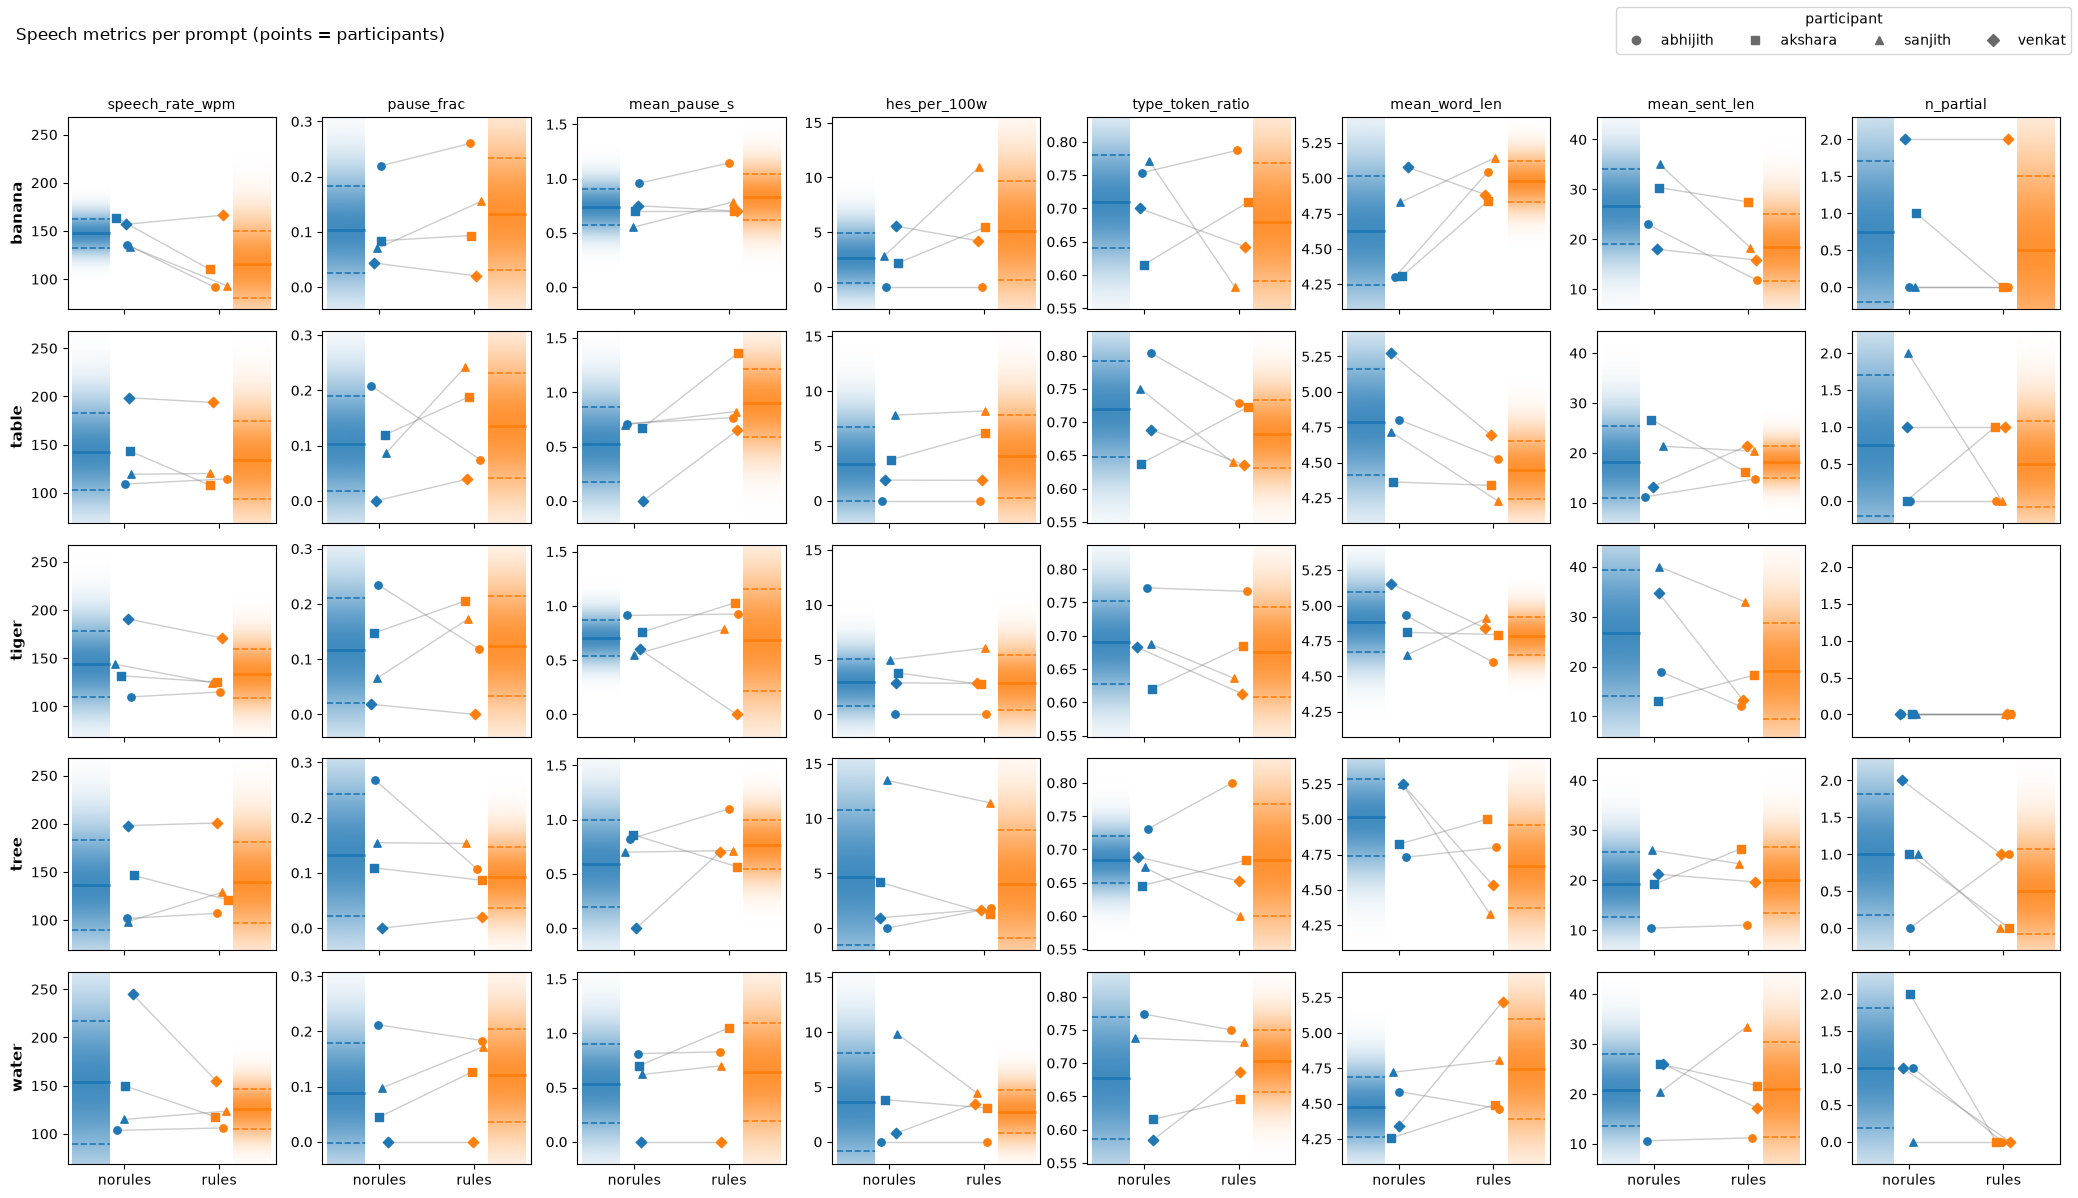

In [17]:
breakdown_grid(wide, show, "prompt", "Speech metrics per prompt (points = participants)")

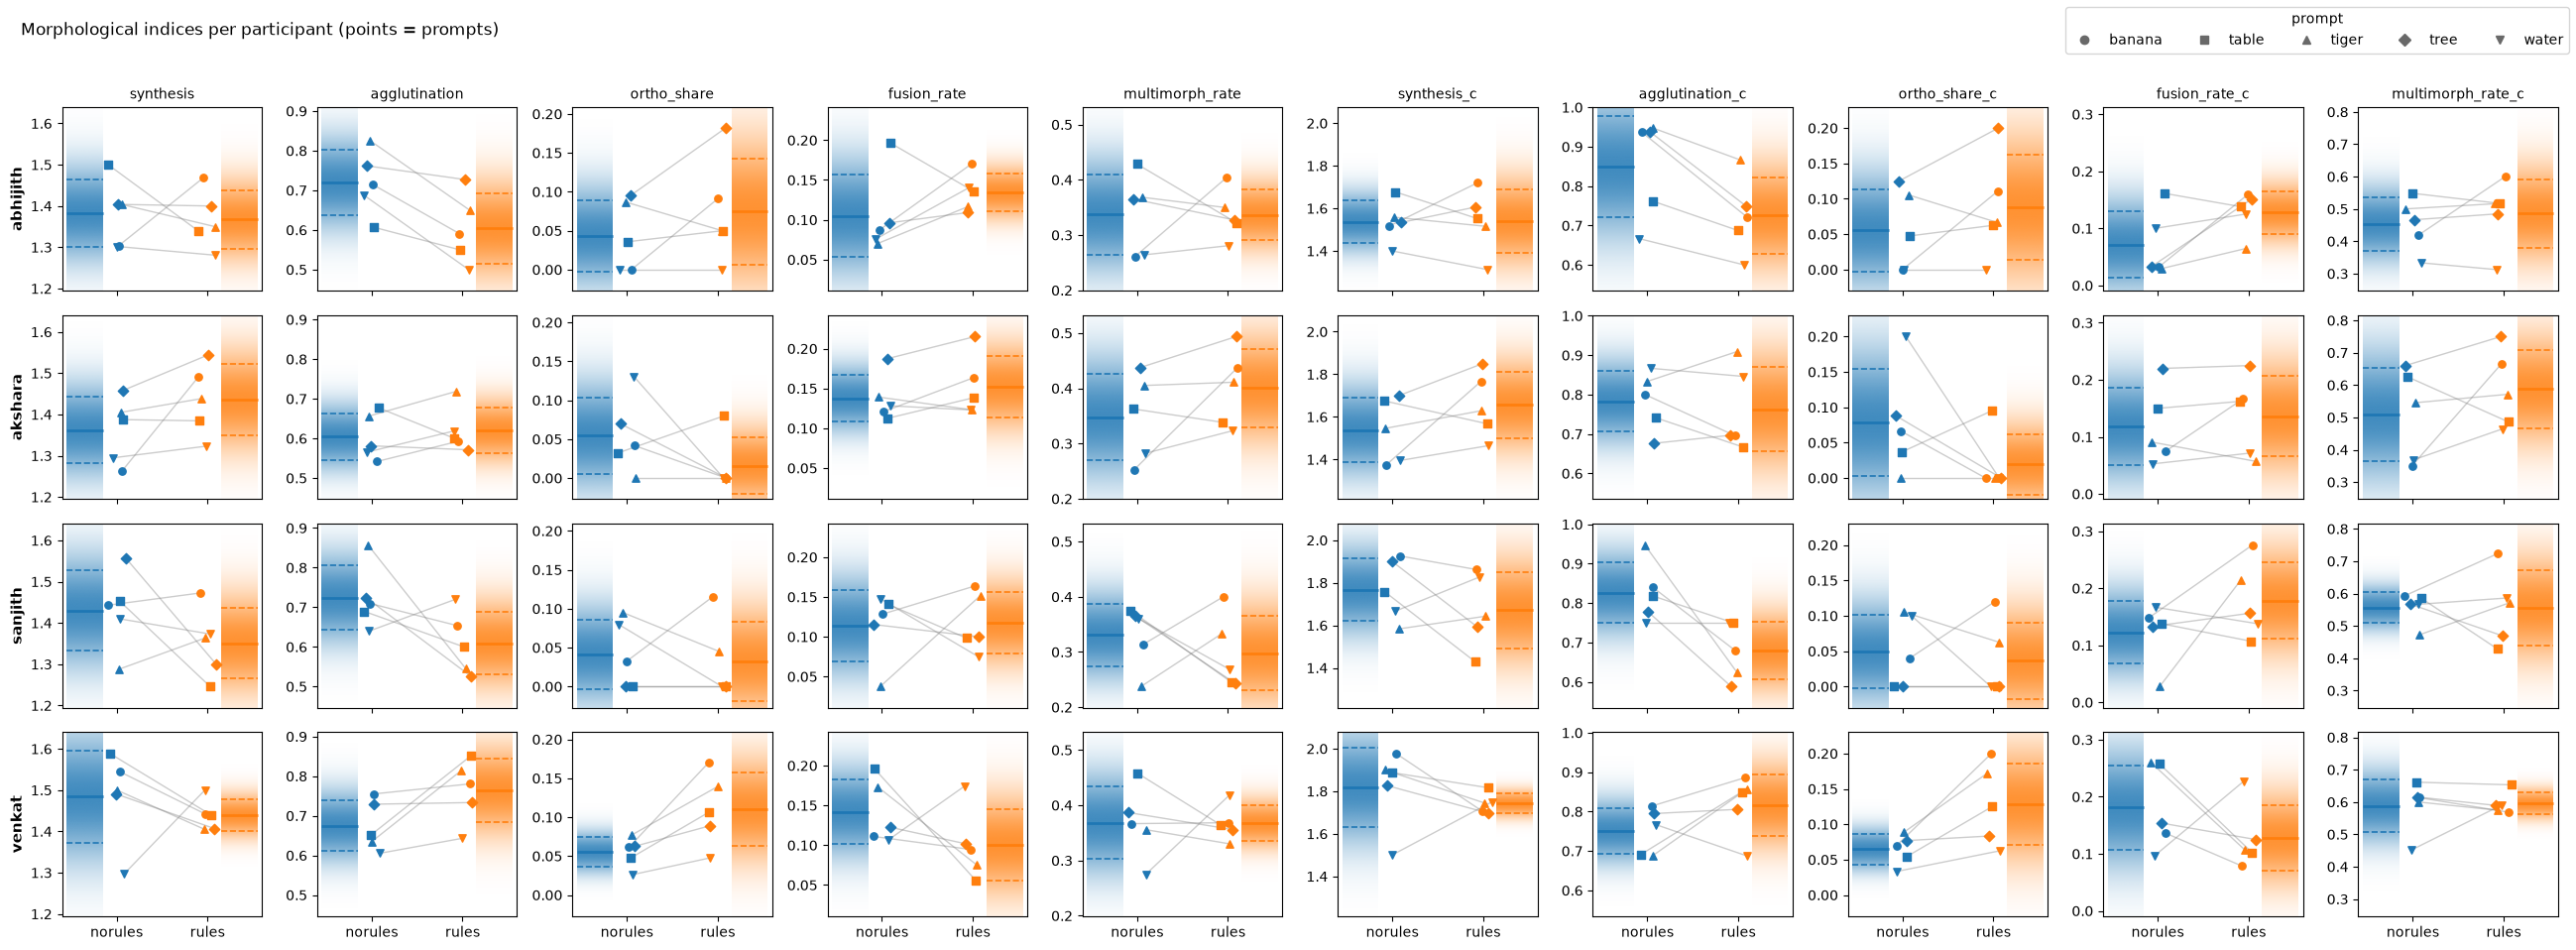

In [18]:
breakdown_grid(mwide, MORPH_METRICS, "participant", "Morphological indices per participant (points = prompts)")

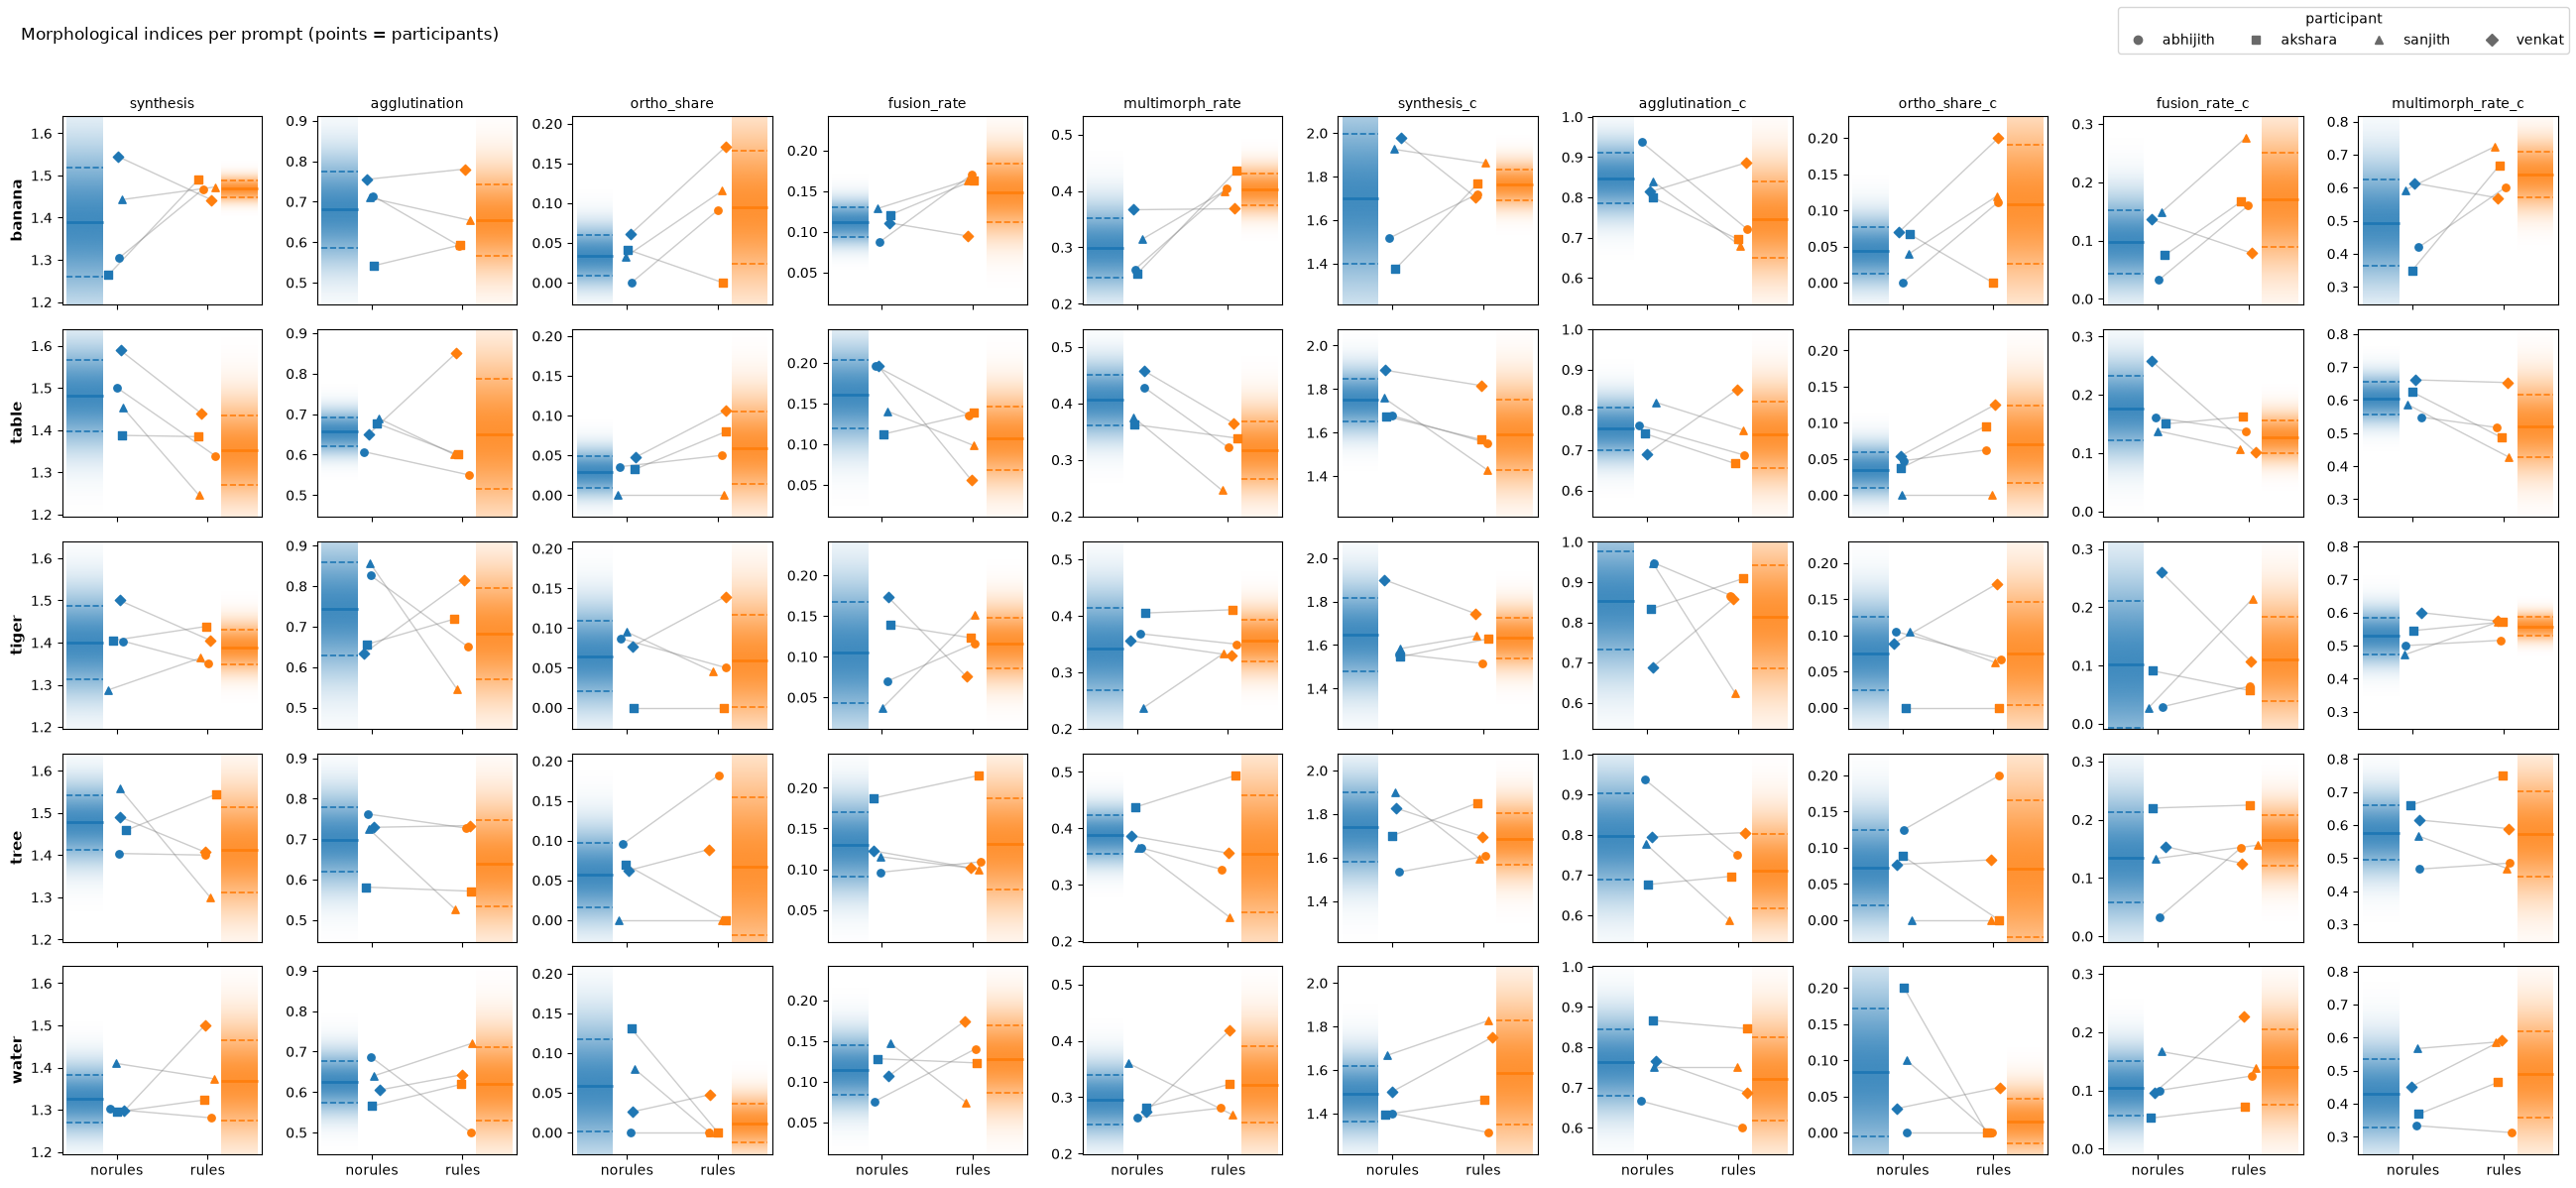

In [19]:
breakdown_grid(mwide, MORPH_METRICS, "prompt", "Morphological indices per prompt (points = participants)")

## Example: difference-based visualisations
All values are paired differences **rules − norules** (same participant, same prompt).

**Forest plot:** black dot = standardised effect d_z (mean diff / SD of diffs); bar = 95% bootstrap CI (5,000 resamples of pairs); coloured dots = each participant's mean difference on the same scale. A CI that crosses 0 means no reliable effect.

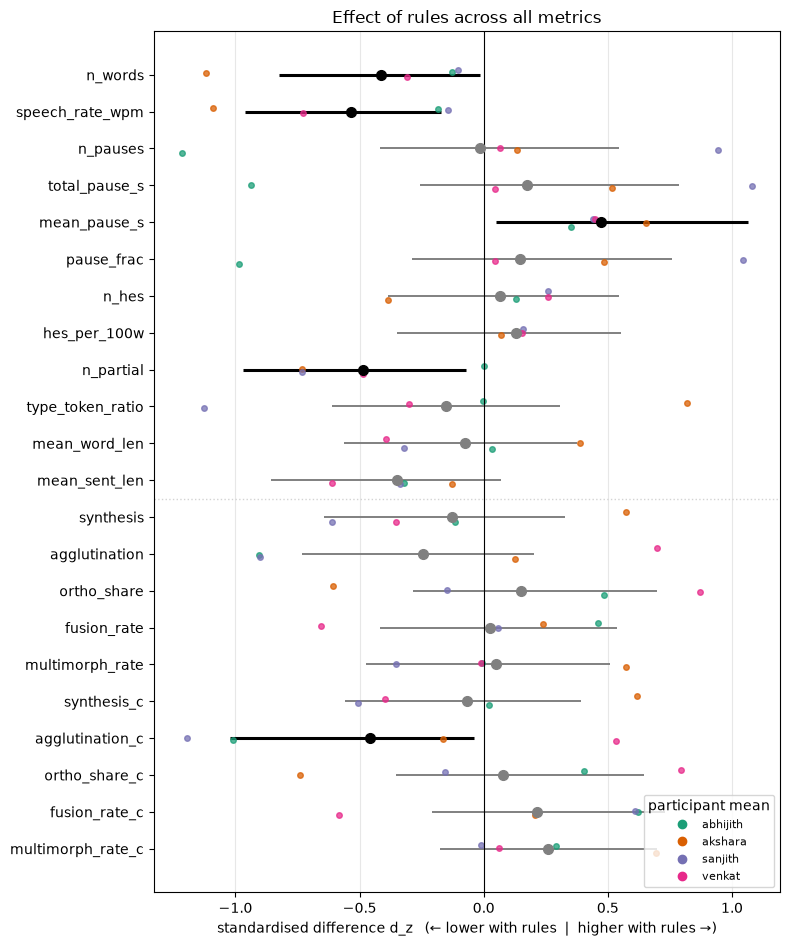

In [20]:
diffs = pd.concat(
    [pd.DataFrame({m: wide[(m, "rules")] - wide[(m, "norules")] for m in METRICS}),
     pd.DataFrame({m: mwide[(m, "rules")] - mwide[(m, "norules")] for m in MORPH_METRICS})], axis=1)
ALL_METRICS = METRICS + MORPH_METRICS

rng = np.random.default_rng(42)
B = 5000
rows = []
for m in ALL_METRICS:
    d = diffs[m].to_numpy()
    sd = d.std(ddof=1)
    if not sd > 0:
        continue
    idx = rng.integers(0, len(d), (B, len(d)))
    bs = d[idx]
    bs_dz = bs.mean(1) / np.where(bs.std(1, ddof=1) > 0, bs.std(1, ddof=1), np.nan)
    lo, hi = np.nanpercentile(bs_dz, [2.5, 97.5])
    rows.append(dict(metric=m, dz=d.mean() / sd, lo=lo, hi=hi, sd=sd,
                     group="morphology" if m in MORPH_METRICS else "speech"))
forest = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)   # top-to-bottom = original order
part_means = diffs.groupby(level="participant").mean()
PCOL = dict(zip(part_means.index, plt.cm.Dark2.colors))

fig, ax = plt.subplots(figsize=(8, 0.38 * len(forest) + 1.2))
for y, r in forest.iterrows():
    sig = r.lo > 0 or r.hi < 0
    ax.hlines(y, r.lo, r.hi, color="black" if sig else "grey", lw=2.2 if sig else 1.4)
    ax.plot(r.dz, y, "o", color="black" if sig else "grey", ms=7, zorder=3)
    for pname, v in part_means[r.metric].items():
        ax.plot(v / r.sd, y + rng.uniform(-0.15, 0.15), "o", color=PCOL[pname], ms=4, alpha=0.75, zorder=2)
ax.axvline(0, color="black", lw=0.8)
split = (forest.group == "speech").idxmax() - 0.5     # boundary between morphology & speech blocks
ax.axhline(split, color="lightgrey", lw=1, ls=":")
ax.set_yticks(range(len(forest)), forest.metric)
ax.set_xlabel("standardised difference d_z   (← lower with rules  |  higher with rules →)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in PCOL.items()],
          title="participant mean", loc="lower right", fontsize=8)
ax.set_title("Effect of rules across all metrics")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

**Difference heatmaps:** rows = participants, columns = prompts; colour = rules − norules (red = higher with rules, blue = lower). Colour scale is symmetric around 0 per metric. The `mean` row/column give the per-prompt and per-participant averages, replacing both breakdown grids.

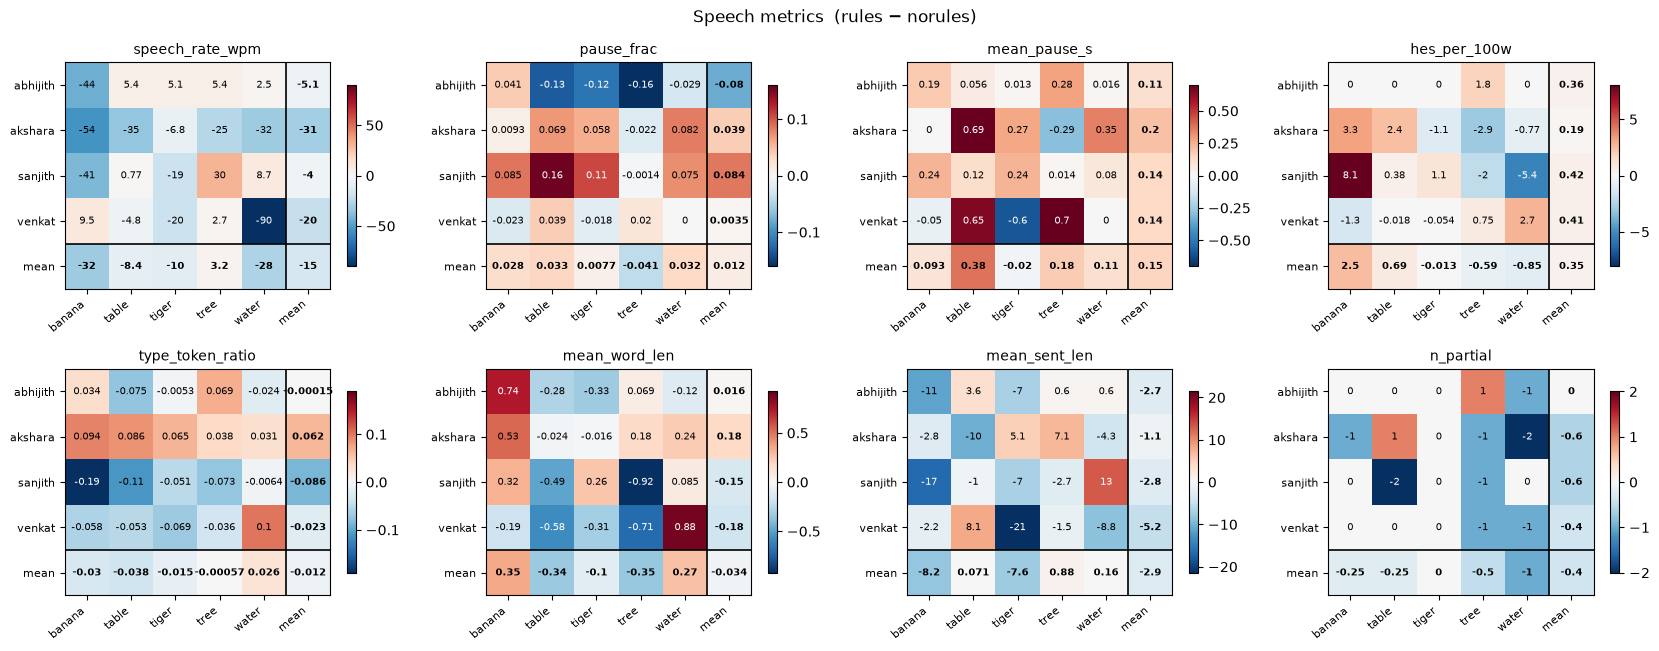

In [21]:
def diff_heatmaps(metrics, title, ncols=4):
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.3 * nrows), squeeze=False)
    for ax, m in zip(axes.flat, metrics):
        mat = diffs[m].unstack("prompt")
        mat["mean"] = mat.mean(axis=1)
        mat.loc["mean"] = mat.mean(axis=0)
        v = np.nanmax(np.abs(mat.to_numpy())) or 1
        im = ax.imshow(mat, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
        for (i, j), val in np.ndenumerate(mat.to_numpy()):
            ax.text(j, i, f"{0 if abs(val) < 1e-9 else val:.2g}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(val) > 0.6 * v else "black",
                    fontweight="bold" if i == mat.shape[0] - 1 or j == mat.shape[1] - 1 else "normal")
        ax.axhline(mat.shape[0] - 1.5, color="black", lw=1.2)
        ax.axvline(mat.shape[1] - 1.5, color="black", lw=1.2)
        ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=40, ha="right", fontsize=8)
        ax.set_yticks(range(mat.shape[0]), mat.index, fontsize=8)
        ax.set_title(m, fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.8)
    for ax in axes.flat[len(metrics):]:
        ax.axis("off")
    fig.suptitle(title + "  (rules − norules)")
    fig.tight_layout()

diff_heatmaps(show, "Speech metrics")

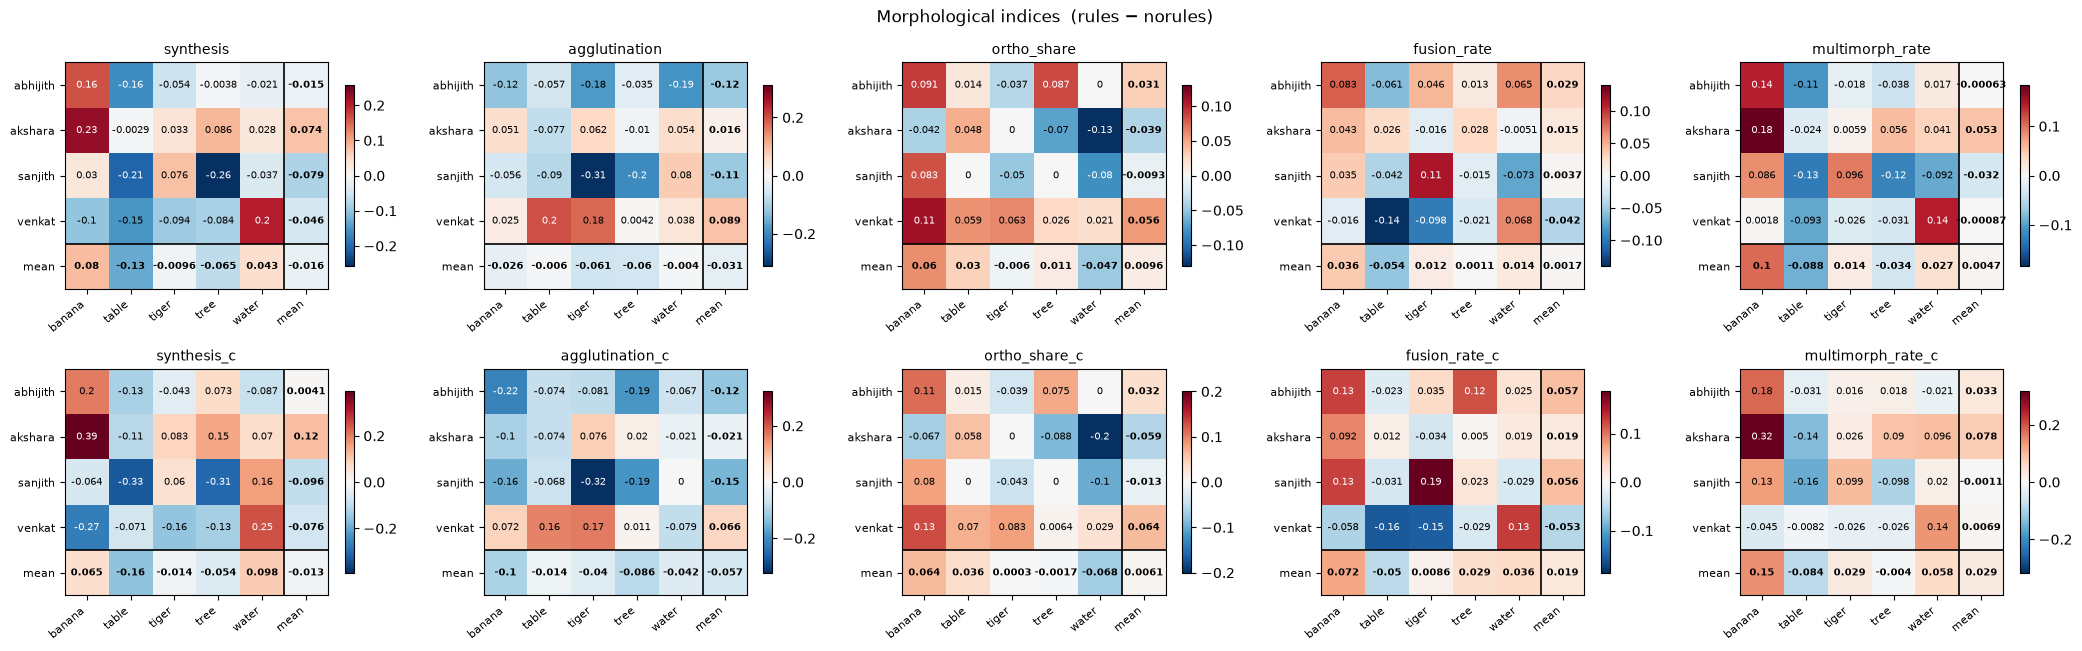

In [22]:
diff_heatmaps(MORPH_METRICS, "Morphological indices", ncols=5)